# Lesson 11: Predicting airline passenger satisfaction

Compare classifiers on the recorded binary satisfaction label. Run from this folder with pandas, scikit-learn, XGBoost, LightGBM, CatBoost, and Matplotlib installed.

**Data:** [Airline Quality Ratings](https://www.kaggle.com/datasets/mikhail1681/airline-quality-ratings). Place `Airline Quality Ratings.csv` in this lesson folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

df = pd.read_csv("Airline Quality Ratings.csv")
print(df["Satisfaction"].value_counts())
df.head()

Satisfaction
Neutral or Dissatisfied    73452
Satisfied                  56428
Name: count, dtype: int64


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


## Split and preprocess

Exclude the passenger identifier. Fit missing-value replacement, categorical encoding, and scaling on the training data for each model. The test split keeps the proportions of both satisfaction labels.

In [2]:
X = df.drop(columns=["ID", "Satisfaction"])
y = df["Satisfaction"].map({"Satisfied": 1, "Neutral or Dissatisfied": 0})
assert y.notna().all()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
categorical = X.select_dtypes(include="object").columns.tolist()
numeric = X.columns.difference(categorical).tolist()
preprocess = ColumnTransformer([
    ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
])

/var/folders/pp/nnh10rws3jl0kc34jz4381080000gn/T/ipykernel_24045/3727032537.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X.select_dtypes(include="object").columns.tolist()


## Compare models

Accuracy measures the overall share of correct predictions. F1 summarizes precision and recall for the satisfied class. ROC AUC uses the predicted probabilities. The majority-class baseline provides a reference.

In [3]:
models = {
    "Majority class": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, n_jobs=1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=100, n_jobs=1, random_state=42, verbosity=-1),
    "CatBoost": CatBoostClassifier(iterations=100, thread_count=1, random_seed=42,
                                   verbose=False, allow_writing_files=False),
}
rows = []
fitted = {}
for name, model in models.items():
    pipeline = Pipeline([("preprocess", preprocess), ("model", model)])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "F1": f1_score(y_test, pred), "ROC AUC": roc_auc_score(y_test, prob)})
    fitted[name] = pipeline
pd.DataFrame(rows).set_index("Model").round(3)

,Accuracy,F1,ROC AUC
Model,,,
Majority class,0.566,0.000,0.500
Logistic regression,0.877,0.856,0.930
Random forest,0.964,0.958,0.994
XGBoost,0.964,0.958,0.995
LightGBM,0.964,0.958,0.995
CatBoost,0.965,0.959,0.995


## Confusion matrix

Inspect the two types of mistakes for the random forest. The matrix uses the held-out test split.

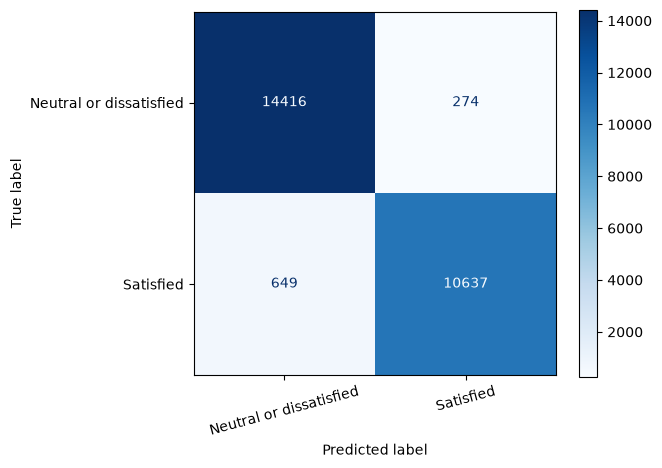

In [4]:
ConfusionMatrixDisplay.from_estimator(
    fitted["Random forest"], X_test, y_test,
    display_labels=["Neutral or dissatisfied", "Satisfied"], cmap="Blues"
)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()